#### Understanding the differences between Baseline and ablated models



In [40]:
import os 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

In [41]:
root_path = os.path.dirname(os.getcwd())
tables_dir = root_path + "/analysis/tables/"
output_dir = tables_dir + "statistical_analysis/"
figures_dir = root_path + "/analysis/figures/statistical_analysis/"
os.makedirs(output_dir, exist_ok=True)
os.makedirs(figures_dir, exist_ok=True)

pd.set_option("display.float_format", "{:.6g}".format)
print(root_path)
print(tables_dir)
print(output_dir)
print(figures_dir)

/home/danbi/Projects/SANAGRAPH
/home/danbi/Projects/SANAGRAPH/analysis/tables/
/home/danbi/Projects/SANAGRAPH/analysis/tables/statistical_analysis/
/home/danbi/Projects/SANAGRAPH/analysis/figures/statistical_analysis/


- `runs.csv` has all the results of the single runs, so there aren't mean and standard deviations. Every row represent a result with a combination of **model, dataset, patternm run and target**.

In [42]:
runs = pd.read_csv(tables_dir + "runs.csv")
comparison = pd.read_csv(tables_dir + "main_comparison.csv")

In [43]:
alpha = 0.05
num_runs = 10
patterns = ["odd", "even", "random", "attr_level", "window"]
logs = comparison.log.drop_duplicates().to_list()
keys = ["log", "model", "pattern", "target"]

print(f"Comparisons to analyze: {len(comparison)}.")

Comparisons to analyze: 1360.


A comparison keep fixed **pattern, target, dataset and ablated variant**.\
For example: Baseline vs model without `time:timestamp` of the dataset `bpi_2012_CZ`, to repair the feature `org:resource` in the pattern `random`.\ 
Then compare ten results of the baseline with ten results of the ablated model

In [44]:
# it groups the ten results of the same experiment 
run_groups = {
    key: group.sort_values("run").value.to_numpy(dtype=float)
    for key, group in runs.groupby(keys)
}

In [45]:
run_groups

{('BPI20_RequestForPayment_CZ',
  'Activity_zero',
  'attr_level',
  'case:Activity'): array([0.97903627, 0.9825756 , 0.96896273, 0.98883748, 0.98393685,
        0.97849172, 0.96705693, 0.97277433, 0.98284787, 0.9730466 ]),
 ('BPI20_RequestForPayment_CZ',
  'Activity_zero',
  'attr_level',
  'case:OrganizationalEntity'): array([0.80347598, 0.79839575, 0.79037434, 0.80160427, 0.82085562,
        0.79411769, 0.80213904, 0.76042783, 0.86925137, 0.81684494]),
 ('BPI20_RequestForPayment_CZ',
  'Activity_zero',
  'attr_level',
  'case:Project'): array([0.81637585, 0.79597318, 0.7299329 , 0.82120806, 0.81744969,
        0.70926178, 0.82523489, 0.74684566, 0.7632215 , 0.78872484]),
 ('BPI20_RequestForPayment_CZ',
  'Activity_zero',
  'attr_level',
  'case:RequestedAmount'): array([0.33685249, 0.30678898, 0.30648807, 0.34534609, 0.30281243,
        0.3184447 , 0.31932306, 0.46920422, 0.38361046, 0.26463622]),
 ('BPI20_RequestForPayment_CZ',
  'Activity_zero',
  'attr_level',
  'case:RfpNumber')

In [46]:
# it detects the comparisons where both the models have the same results in their runs.
constant_pairs = []
for row in comparison.itertuples(index=False):
    full = run_groups[(row.log, "full", row.pattern, row.target)]
    variant = run_groups[(row.log, row.model, row.pattern, row.target)]
    constant_pairs.append(np.ptp(full) == 0 and np.ptp(variant) == 0)

In [47]:
constant_pairs

[False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 True,
 False,
 False,
 False,
 True,
 False,
 False,
 False,
 False,
 True,
 False,
 False,
 False,
 True,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 True,
 False,
 False,
 False,
 False,
 True,
 False,
 False,
 False,
 True,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 True,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 True,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 True,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 True,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 True,
 False,
 False,
 True,
 False,
 False,
 False,
 False,
 False,
 True,
 False,
 False,
 True,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 True,
 False,
 False,
 False,
 False,
 False,


#### An example

Let's choose an ablated variant, a target and a pattern. The table shows the values of the full model and the variant model.

In [48]:
selected_log = "bpi_2012_CZ"
selected_model = "ablate::time:timestamp"
selected_target = "org:resource"
selected_pattern = "random"

example_mask = (
    comparison.log.eq(selected_log) & comparison.model.eq(selected_model)
    & comparison.target.eq(selected_target) & comparison.pattern.eq(selected_pattern)
)
example_index = comparison.index[example_mask][0]


In [49]:
example_runs = pd.DataFrame({
    "run": np.arange(num_runs),
    "full": run_groups[(selected_log, "full", selected_pattern, selected_target)],
    "variant": run_groups[(selected_log, selected_model, selected_pattern, selected_target)],
})
example_runs.set_index("run", inplace=True)
example_runs


,full,variant
run,,
0,0.643403,0.652563
1,0.649622,0.637605
2,0.645798,0.648067
3,0.636597,0.654916
4,0.64521,0.638655
5,0.630294,0.650672
6,0.641261,0.652647
7,0.631345,0.636555
8,0.642983,0.64


#### Mean, Standard Deviation and Delta

Like the other notebooks, it uses accuracy for the categorical attributes and MAE for the numerical ones. If the delta is **negative** we have an improvong of the performances, while a positive value indicates a worsening. \
Another example of delta below:

In [50]:
results = comparison.copy().reset_index(drop=True)
is_categorical = results.kind.eq("categorical")

results.loc[[example_index], [
    "metric", "full_mean", "full_std", "variant_mean", "variant_std", "delta",
]].round(6)


,metric,full_mean,full_std,variant_mean,variant_std,delta
594,accuracy,0.641731,0.007014,0.646441,0.007347,-0.00471


#### Testing the results 

We have ten runs for the full model and ten runs for the ablated variant, so it's useful to use a test that compares two groups of runs and consider the variability of each of them. For that reason the notebook exploit the Welch test, a test that allows the groups to have different variances: there isn't the need to suppose that full and variant oscillate to the same extent. \
This kind of test is bilateral, it consider improvement and worsening too. This test needs only mean, standard deviation and the number of runs, I used the statistics calculated on the notebook 01. The function `ttest_ind_from_stats` receive this data.

#### Individuating the not estmable cases

If both the series are constant, the observed variability is null and the Welch test isn't estimable

In [51]:
estimable = pd.Series(~np.array(constant_pairs), index=results.index)
results["test_status"] = np.where(estimable, "ok", "both series are constant")
results["p_value"] = np.nan

print("Estimable tests:", int(estimable.sum()))
print("Cases with constat series:", int((~estimable).sum()))


Estimable tests: 1261
Cases with constat series: 99


In [52]:
estimable

0        True
1        True
2        True
3        True
4        True
        ...  
1355     True
1356     True
1357     True
1358    False
1359     True
Length: 1360, dtype: bool

The next cell execute the test and create a columns `p_value` where the p-value of the test is stored for each case.

In [53]:
valid = results.loc[estimable]
test = stats.ttest_ind_from_stats(
    mean1=valid.full_mean.to_numpy(), std1=valid.full_std.to_numpy(), nobs1=valid.full_n_runs.to_numpy(),
    mean2=valid.variant_mean.to_numpy(), std2=valid.variant_std.to_numpy(), nobs2=valid.variant_n_runs.to_numpy(),
    equal_var=False, alternative="two-sided",
)
results.loc[estimable, "p_value"] = test.pvalue


In [ ]:
results

,log,model,excluded_feature,pattern,target,kind,metric,variant_mean,variant_std,variant_n_runs,full_mean,full_std,full_n_runs,delta,delta_accuracy_pp,test_status,p_value
0,BPI20_RequestForPayment_CZ,Activity_zero,Activity,attr_level,case:Activity,categorical,accuracy,0.977757,0.0070799,10,0.970215,0.0100577,10,-0.00754151,-0.754151,ok,0.0701742
1,BPI20_RequestForPayment_CZ,Activity_zero,Activity,attr_level,case:OrganizationalEntity,categorical,accuracy,0.805749,0.0276867,10,0.832995,0.0304487,10,0.027246,2.7246,ok,0.0508587
2,BPI20_RequestForPayment_CZ,Activity_zero,Activity,attr_level,case:Project,categorical,accuracy,0.781423,0.0417297,10,0.811919,0.0234664,10,0.0304966,3.04966,ok,0.0633505
3,BPI20_RequestForPayment_CZ,Activity_zero,Activity,attr_level,case:RequestedAmount,numerical,mae,0.335351,0.0563705,10,0.294827,0.0433466,10,0.0405241,NaN,ok,0.0894044
4,BPI20_RequestForPayment_CZ,Activity_zero,Activity,attr_level,case:RfpNumber,categorical,accuracy,0.0377348,0.00124115,10,0.0379871,0.00130996,10,0.000252312,0.0252312,ok,0.663664
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1355,sp2020_CZ,ablate::time:timestamp,time:timestamp,random,org:resource,categorical,accuracy,0.969122,0.00136332,10,0.969065,0.00270984,10,-5.70059e-05,-0.00570059,ok,0.953497
1356,sp2020_CZ,ablate::time:timestamp,time:timestamp,window,Activity,categorical,accuracy,0.742244,0.00548269,10,0.738783,0.00536648,10,-0.00346129,-0.346129,ok,0.170791
1357,sp2020_CZ,ablate::time:timestamp,time:timestamp,window,DEVICETYPE,categorical,accuracy,0.998007,0.000320394,10,0.997399,0.000490605,10,-0.000607562,-0.0607562,ok,0.00489387
1358,sp2020_CZ,ablate::time:timestamp,time:timestamp,window,REPAIR_IN_TIME_5D,categorical,accuracy,1,0,10,1,0,10,0,0,both series are constant,NaN


#### Interpreting the p-value

The notebook uses `alpha = 0.05` as the significance threshold:

- `p_value ≤ 0.05`: evidence of a difference between the full model and the variant.
- `p_value > 0.05`: insufficient evidence of a difference. This does not prove that the models are equivalent.

I kept the original p-values, without multiple-comparison correction.
The threshold applies to each comparison individually.

The direction of the performance change will be determined using the delta.

In [55]:
results["significant"] = estimable & results.p_value.le(alpha)
results["test_method"] = "Welch, two-sided, independent samples"
results["p_adjustment"] = "none"
results["alpha"] = alpha

In [56]:
results

,log,model,excluded_feature,pattern,target,kind,metric,variant_mean,variant_std,variant_n_runs,...,full_std,full_n_runs,delta,delta_accuracy_pp,test_status,p_value,significant,test_method,p_adjustment,alpha
0,BPI20_RequestForPayment_CZ,Activity_zero,Activity,attr_level,case:Activity,categorical,accuracy,0.977757,0.0070799,10,...,0.0100577,10,-0.00754151,-0.754151,ok,0.0701742,False,"Welch, two-sided, independent samples",none,0.05
1,BPI20_RequestForPayment_CZ,Activity_zero,Activity,attr_level,case:OrganizationalEntity,categorical,accuracy,0.805749,0.0276867,10,...,0.0304487,10,0.027246,2.7246,ok,0.0508587,False,"Welch, two-sided, independent samples",none,0.05
2,BPI20_RequestForPayment_CZ,Activity_zero,Activity,attr_level,case:Project,categorical,accuracy,0.781423,0.0417297,10,...,0.0234664,10,0.0304966,3.04966,ok,0.0633505,False,"Welch, two-sided, independent samples",none,0.05
3,BPI20_RequestForPayment_CZ,Activity_zero,Activity,attr_level,case:RequestedAmount,numerical,mae,0.335351,0.0563705,10,...,0.0433466,10,0.0405241,NaN,ok,0.0894044,False,"Welch, two-sided, independent samples",none,0.05
4,BPI20_RequestForPayment_CZ,Activity_zero,Activity,attr_level,case:RfpNumber,categorical,accuracy,0.0377348,0.00124115,10,...,0.00130996,10,0.000252312,0.0252312,ok,0.663664,False,"Welch, two-sided, independent samples",none,0.05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1355,sp2020_CZ,ablate::time:timestamp,time:timestamp,random,org:resource,categorical,accuracy,0.969122,0.00136332,10,...,0.00270984,10,-5.70059e-05,-0.00570059,ok,0.953497,False,"Welch, two-sided, independent samples",none,0.05
1356,sp2020_CZ,ablate::time:timestamp,time:timestamp,window,Activity,categorical,accuracy,0.742244,0.00548269,10,...,0.00536648,10,-0.00346129,-0.346129,ok,0.170791,False,"Welch, two-sided, independent samples",none,0.05
1357,sp2020_CZ,ablate::time:timestamp,time:timestamp,window,DEVICETYPE,categorical,accuracy,0.998007,0.000320394,10,...,0.000490605,10,-0.000607562,-0.0607562,ok,0.00489387,True,"Welch, two-sided, independent samples",none,0.05
1358,sp2020_CZ,ablate::time:timestamp,time:timestamp,window,REPAIR_IN_TIME_5D,categorical,accuracy,1,0,10,...,0,10,0,0,both series are constant,NaN,False,"Welch, two-sided, independent samples",none,0.05


#### Assigning an outcome to every comparison

Combining the p-value with the delta sign:
- `improvement`: the p-value is less than 0,05 and delta is negative.
- `worsening`: the p-value is less than 0,05 and delta is positive.
- `inconclusive`: the test is estimable but the p-value is more 0,05.
- `not estimable`: the two series are both constant. They don't have p-value.

In [57]:
results["outcome"] = "inconclusive"
results.loc[~estimable, "outcome"] = "not_estimable"
results.loc[results.significant & results.delta.lt(0), "outcome"] = "improvement"
results.loc[results.significant & results.delta.gt(0), "outcome"] = "worsening"
results["intervention"] = np.where(
    results.model.eq("Activity_zero"), "input_zero", "attribute_removal"
)

In [60]:
results

,log,model,excluded_feature,pattern,target,kind,metric,variant_mean,variant_std,variant_n_runs,...,delta,delta_accuracy_pp,test_status,p_value,significant,test_method,p_adjustment,alpha,outcome,intervention
0,BPI20_RequestForPayment_CZ,Activity_zero,Activity,attr_level,case:Activity,categorical,accuracy,0.977757,0.0070799,10,...,-0.00754151,-0.754151,ok,0.0701742,False,"Welch, two-sided, independent samples",none,0.05,inconclusive,input_zero
1,BPI20_RequestForPayment_CZ,Activity_zero,Activity,attr_level,case:OrganizationalEntity,categorical,accuracy,0.805749,0.0276867,10,...,0.027246,2.7246,ok,0.0508587,False,"Welch, two-sided, independent samples",none,0.05,inconclusive,input_zero
2,BPI20_RequestForPayment_CZ,Activity_zero,Activity,attr_level,case:Project,categorical,accuracy,0.781423,0.0417297,10,...,0.0304966,3.04966,ok,0.0633505,False,"Welch, two-sided, independent samples",none,0.05,inconclusive,input_zero
3,BPI20_RequestForPayment_CZ,Activity_zero,Activity,attr_level,case:RequestedAmount,numerical,mae,0.335351,0.0563705,10,...,0.0405241,NaN,ok,0.0894044,False,"Welch, two-sided, independent samples",none,0.05,inconclusive,input_zero
4,BPI20_RequestForPayment_CZ,Activity_zero,Activity,attr_level,case:RfpNumber,categorical,accuracy,0.0377348,0.00124115,10,...,0.000252312,0.0252312,ok,0.663664,False,"Welch, two-sided, independent samples",none,0.05,inconclusive,input_zero
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1355,sp2020_CZ,ablate::time:timestamp,time:timestamp,random,org:resource,categorical,accuracy,0.969122,0.00136332,10,...,-5.70059e-05,-0.00570059,ok,0.953497,False,"Welch, two-sided, independent samples",none,0.05,inconclusive,attribute_removal
1356,sp2020_CZ,ablate::time:timestamp,time:timestamp,window,Activity,categorical,accuracy,0.742244,0.00548269,10,...,-0.00346129,-0.346129,ok,0.170791,False,"Welch, two-sided, independent samples",none,0.05,inconclusive,attribute_removal
1357,sp2020_CZ,ablate::time:timestamp,time:timestamp,window,DEVICETYPE,categorical,accuracy,0.998007,0.000320394,10,...,-0.000607562,-0.0607562,ok,0.00489387,True,"Welch, two-sided, independent samples",none,0.05,improvement,attribute_removal
1358,sp2020_CZ,ablate::time:timestamp,time:timestamp,window,REPAIR_IN_TIME_5D,categorical,accuracy,1,0,10,...,0,0,both series are constant,NaN,False,"Welch, two-sided, independent samples",none,0.05,not_estimable,attribute_removal


#### Summary for dataset and metric

It counts the outcomes of every comparison. Every row represents a dataset with accuracy and MAE separated.

In [61]:
outcomes = ["improvement", "worsening", "inconclusive", "not_estimable"]
overview = pd.crosstab([results.log, results.metric], results.outcome)
overview = overview.reindex(columns=outcomes, fill_value=0)
overview["comparisons"] = overview.sum(axis=1)
overview = overview.reset_index().rename_axis(columns=None)
overview


,log,metric,improvement,worsening,inconclusive,not_estimable,comparisons
0,BPI20_RequestForPayment_CZ,accuracy,27,32,239,62,360
1,BPI20_RequestForPayment_CZ,mae,8,10,72,0,90
2,bpi_2012_CZ,accuracy,23,27,50,0,100
3,bpi_2012_CZ,mae,9,0,41,0,50
4,bpi_2013_CZ,accuracy,9,111,466,19,605
5,bpi_2013_CZ,mae,0,0,55,0,55
6,sp2020_CZ,accuracy,13,7,42,18,80
7,sp2020_CZ,mae,0,0,20,0,20


#### Summary for removed feature

In [62]:
feature_summary = pd.crosstab(
    [results.log, results.model, results.excluded_feature, results.intervention, results.metric],
    results.outcome,
).reindex(columns=outcomes, fill_value=0)
feature_summary["comparisons"] = feature_summary.sum(axis=1)
feature_summary = feature_summary.reset_index().rename_axis(columns=None)

feature_totals = feature_summary.groupby(
    ["log", "model", "excluded_feature", "intervention"], as_index=False
)[outcomes + ["comparisons"]].sum()
feature_totals


,log,model,excluded_feature,intervention,improvement,worsening,inconclusive,not_estimable,comparisons
0,BPI20_RequestForPayment_CZ,Activity_zero,Activity,input_zero,5,9,24,7,45
1,BPI20_RequestForPayment_CZ,ablate::case:Activity,case:Activity,attribute_removal,0,2,39,4,45
2,BPI20_RequestForPayment_CZ,ablate::case:OrganizationalEntity,case:OrganizationalEntity,attribute_removal,5,5,28,7,45
3,BPI20_RequestForPayment_CZ,ablate::case:Project,case:Project,attribute_removal,0,4,34,7,45
4,BPI20_RequestForPayment_CZ,ablate::case:RequestedAmount,case:RequestedAmount,attribute_removal,2,6,31,6,45
5,BPI20_RequestForPayment_CZ,ablate::case:RfpNumber,case:RfpNumber,attribute_removal,10,4,28,3,45
6,BPI20_RequestForPayment_CZ,ablate::case:Task,case:Task,attribute_removal,4,1,33,7,45
7,BPI20_RequestForPayment_CZ,ablate::org:resource,org:resource,attribute_removal,2,1,35,7,45
8,BPI20_RequestForPayment_CZ,ablate::org:role,org:role,attribute_removal,2,4,32,7,45
9,BPI20_RequestForPayment_CZ,ablate::time:timestamp,time:timestamp,attribute_removal,5,6,27,7,45


#### Graphs of the improvements

Here below a graph for each dataset, every row represents a removed feature, or zeroed in the case of `Activity`, and has two bars of different type:
- **Blue**: how many comparisons presents an improvement compared to the baseline.
- **Orange**: how many comparisons presents a worsening compared to the baseline.

The value `n` next to the feature indicates all the available comparisons, included the ones that were not estimable or inconcludent. It is calculated like this:

**n = number of remained targets * 5 patterns**

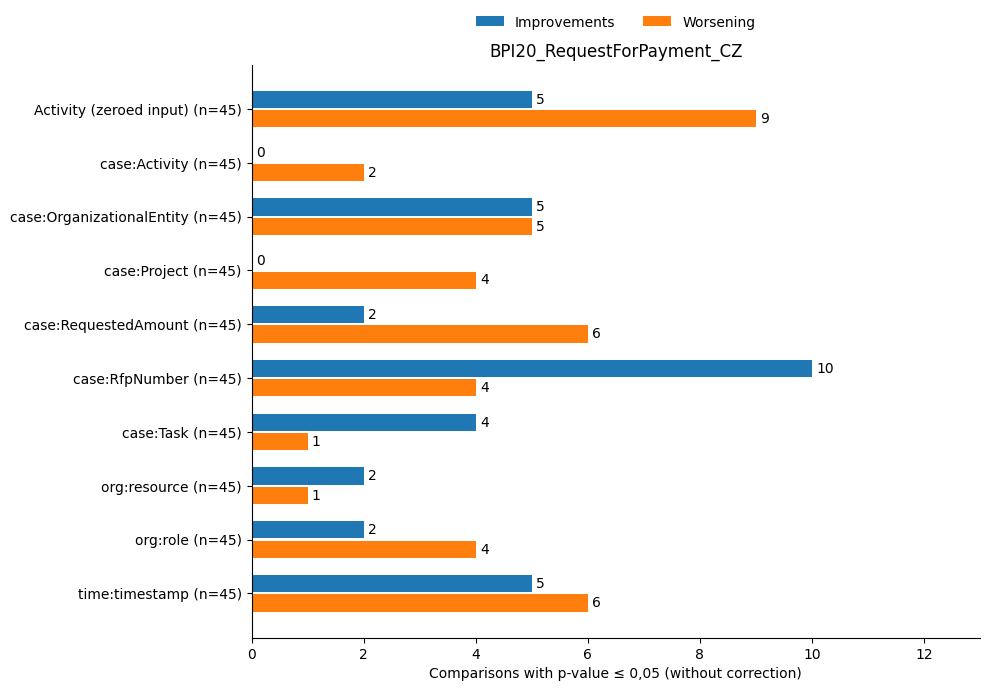

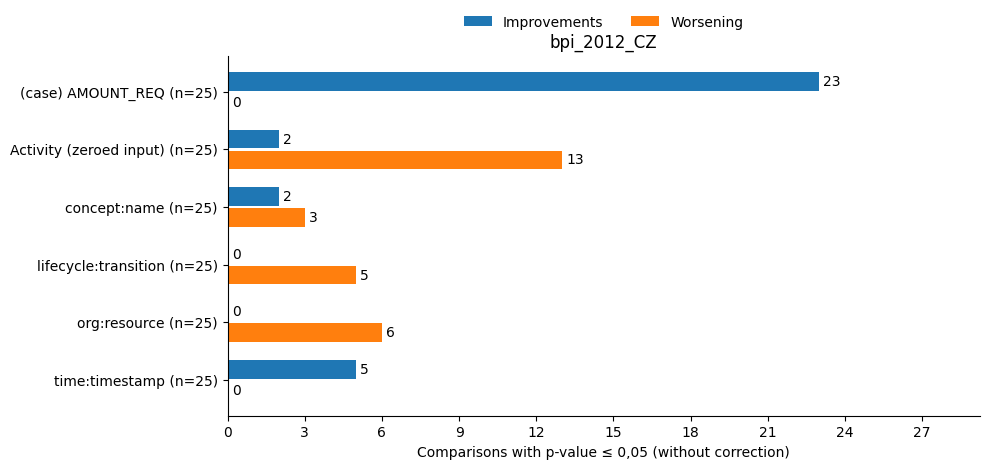

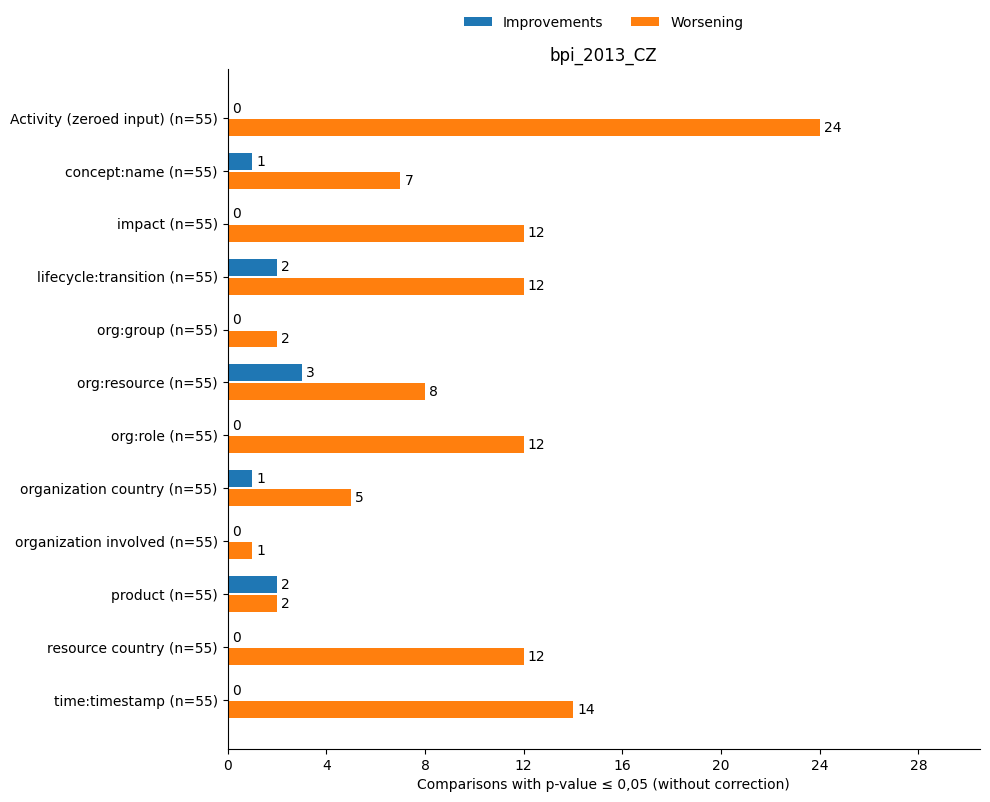

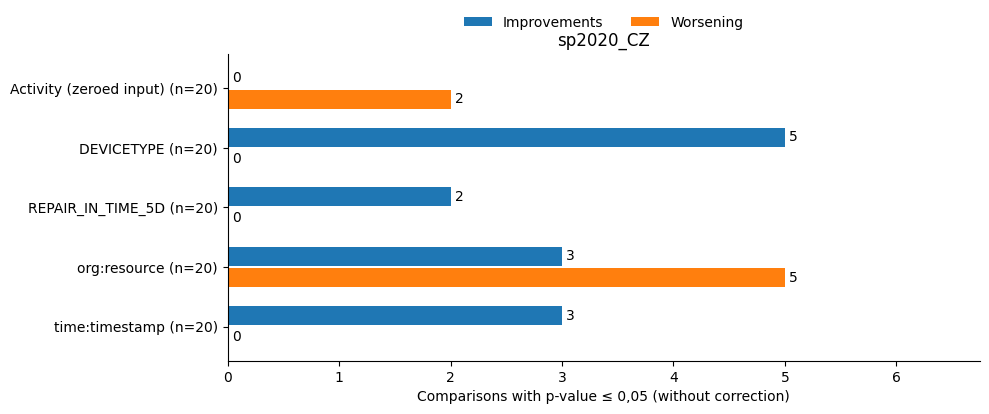

In [70]:
for log in logs:
    data = feature_totals[feature_totals.log == log].sort_values("excluded_feature")
    labels = [
        ("Activity (zeroed input)" if row.excluded_feature == "Activity" else row.excluded_feature) + f" (n={row.comparisons})"
        for row in data.itertuples()
    ]

    y = np.arange(len(data))
    fig, ax = plt.subplots(figsize=(10, max(4, len(data) * 0.55 + 1.5)))
    improvement_bars = ax.barh(
        y - 0.18, data.improvement, height=0.32,
        color="tab:blue", label="Improvements",
    )
    worsening_bars = ax.barh(
        y + 0.18, data.worsening, height=0.32,
        color="tab:orange", label="Worsening",
    )
    ax.bar_label(improvement_bars, padding=3)
    ax.bar_label(worsening_bars, padding=3)
    ax.set_yticks(y, labels)
    ax.invert_yaxis()
    largest = max(data.improvement.max(), data.worsening.max(), 1)
    ax.set_xlim(0, largest * 1.25 + 0.5)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.set_xlabel("Comparisons with p-value ≤ 0,05 (without correction)")
    ax.set_title(log)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.04), ncol=2, frameon=False)
    fig.tight_layout()
    fig.savefig(figures_dir + "03_welch_uncorrected_" + log + ".png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)


#### Which targets and patterns change?

The table `supported` created in the following cell is useful to see which results have produced the bars in the graph. It only contains that rows that have p-value equal or less to 0,05 and shows which targets and patterns are involved.

In [72]:
supported = results[results.significant].sort_values(
    ["log", "excluded_feature", "metric", "target", "pattern"]
)
supported.head(20)[[
    "log", "excluded_feature", "target", "pattern", "metric",
    "full_mean", "variant_mean", "p_value", "outcome",
]]


,log,excluded_feature,target,pattern,metric,full_mean,variant_mean,p_value,outcome
10,BPI20_RequestForPayment_CZ,Activity,case:OrganizationalEntity,even,accuracy,0.946368,0.935642,0.0369305,worsening
19,BPI20_RequestForPayment_CZ,Activity,case:OrganizationalEntity,odd,accuracy,0.942261,0.931711,0.0457282,worsening
37,BPI20_RequestForPayment_CZ,Activity,case:OrganizationalEntity,window,accuracy,0.937686,0.92484,0.0193588,worsening
11,BPI20_RequestForPayment_CZ,Activity,case:Project,even,accuracy,0.936412,0.919937,0.0437531,worsening
14,BPI20_RequestForPayment_CZ,Activity,case:Task,even,accuracy,0.755604,0.758153,0.0136911,improvement
23,BPI20_RequestForPayment_CZ,Activity,case:Task,odd,accuracy,0.752207,0.754383,0.0451413,improvement
32,BPI20_RequestForPayment_CZ,Activity,case:Task,random,accuracy,0.753975,0.755807,0.0105447,improvement
41,BPI20_RequestForPayment_CZ,Activity,case:Task,window,accuracy,0.753892,0.756125,0.0142016,improvement
6,BPI20_RequestForPayment_CZ,Activity,org:resource,attr_level,accuracy,0.991329,0.966094,7.59247e-06,worsening
7,BPI20_RequestForPayment_CZ,Activity,org:role,attr_level,accuracy,0.967444,0.934279,3.08557e-08,worsening


In [73]:
results.to_csv(output_dir + "statistical_comparison.csv", index=False)
overview.to_csv(output_dir + "overview.csv", index=False)
feature_summary.to_csv(output_dir + "feature_summary.csv", index=False)
feature_totals.to_csv(output_dir + "feature_totals.csv", index=False)
supported.to_csv(output_dir + "supported_comparisons.csv", index=False)
